# Compare the three systems

You'll put the same amg settings side by side on matrix, tioga and tuolumne, see which system wins each one, and find the functions that make each system fast or slow.
It takes about 15 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import DataFrame, Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("../figures", exist_ok=True)
SYSTEMS = ["matrix", "tioga", "tuolumne"]

The sweep ran on three LLNL systems.
The runs use only the CPU cores, so the CPU and the network are what differ.

| System | CPU | Cores per node | Interconnect |
|---|---|---|---|
| matrix | Intel Xeon Platinum 8480+ | 112 | InfiniBand |
| tioga | AMD Trento | 64 | HPE Slingshot 11 |
| tuolumne | AMD MI300A (4th generation EPYC cores) | 96 | HPE Slingshot 11 |

The [LLNL compute platforms table](https://hpc.llnl.gov/hardware/compute-platforms) lists the rest of each system.

## 1. Find the settings that ran on each system

A setting is an application, an input, a number of nodes and a number of processes per node.
Read the time of `main` of each run and put the systems of one setting in one row.

In [3]:
setting = ["app", "unique_input", "nodes", "ppn"]
main = tv.filter((col("gtype") == "func") & (col("path") == "main")).collect().merge(runs, on="run")
main = main.assign(t=main["dur.p50"] / 1e6)
by_system = main.pivot_table(values="t", index=setting, columns="system", aggfunc="median").to_pandas()
ran = by_system[SYSTEMS].notna()
by_system["systems"] = ran.apply(lambda row: "+".join(s for s in SYSTEMS if row[s]), axis=1)
display(by_system.groupby(["app", "systems"]).size())

app     systems              
amg     matrix                     53
        matrix+tioga                5
        matrix+tioga+tuolumne     108
        matrix+tuolumne           140
        tioga                       3
        tioga+tuolumne              2
        tuolumne                   22
laghos  matrix                   1672
        tioga                     103
minife  tioga                      84
        tuolumne                    1
dtype: int64

Only amg ran on all three systems, in 108 settings.
laghos and minife never ran one setting on two systems, so the rest of this page uses amg.

## 2. See which system wins each setting

Divide the time of each system by the time of the fastest system of the same setting.
The winner gets 1, and a system at 2 takes twice as long as the winner.
No system is the baseline, so all three show up.

In [4]:
common = by_system[by_system["systems"] == "matrix+tioga+tuolumne"]
times = common[SYSTEMS]
rel = times.div(times.min(axis=1), axis=0)
display(times.idxmin(axis=1).value_counts())
display(rel.groupby(common["ppn"]).median().round(2))

matrix      50
tuolumne    40
tioga       18
Name: count, dtype: int64

,matrix,tioga,tuolumne
ppn,,,
1,1.12,1.00,1.05
2,1.03,1.11,1.01
4,1.03,1.31,1.00
8,1.00,1.46,1.30
16,1.00,105.76,1.10
32,1.08,93.24,1.00


Up to 8 processes per node the three systems stay within about 50% of each other.
From 16 processes per node tioga takes about 100 times longer than the winner, while matrix and tuolumne stay within 10%.

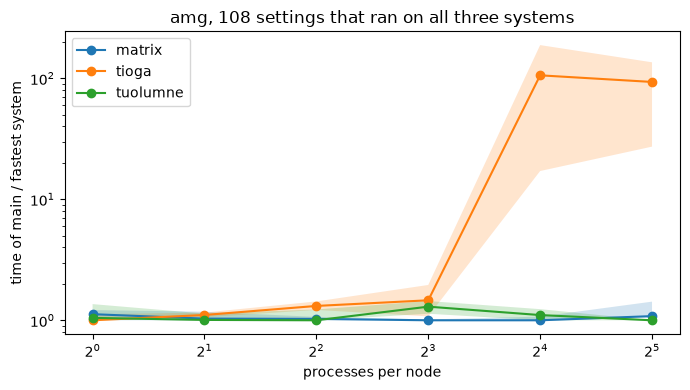

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for system in SYSTEMS:
    q = rel[system].groupby(common["ppn"]).quantile([0.25, 0.5, 0.75]).unstack()
    ax.plot(q.index, q[0.5], marker="o", label=system)
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("processes per node")
ax.set_ylabel("time of main / fastest system")
ax.set_title("amg, 108 settings that ran on all three systems")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/systems-ratio.png", dpi=120)

![Time of main relative to the fastest system of each setting](../figures/systems-ratio.png)

The line is the median over the settings, and the band holds the middle half of them.

## 3. Compare the functions of one setting

The time of `main` says who wins, not why.
Take amg `p1_n64x64x32` on one node, and compare the self time of each function on the three systems, per process.
Self time is a path's time minus its children's, as in [Build the call tree of one amg run](05-build-the-call-tree-of-one-run.ipynb), now for many runs at once.

In [6]:
def self_time(func):
    children = func.groupby(["run", "parent"])[["dur.sum"]].sum()
    children = children.rename(columns={"parent": "path", "dur.sum": "children"})
    tree = func.merge(children, on=["run", "path"], how="left")
    tree = tree.assign(children=tree["children"].fillna(0))
    return tree.assign(self_s=(tree["dur.sum"] - tree["children"]) / 1e6)


def per_function(run_ids, info):
    func = tv.filter((col("gtype") == "func") & col("run").isin(run_ids)).collect()
    tree = self_time(func).merge(info, on="run")
    tree = tree.assign(self_pp=tree["self_s"] / (tree["nodes"] * tree["ppn"]))
    keys = ["system", "app", "unique_input", "nodes", "ppn"]
    by_run = tree.groupby(["run", *keys, "name"])[["self_pp"]].sum()
    return by_run.groupby([*keys, "name"])[["self_pp"]].median()


one = runs[(runs["app"] == "amg") & (runs["unique_input"] == "p1_n64x64x32") & (runs["nodes"] == 1)]
one = one[one["ppn"].isin([4, 16])]
fn = per_function(one["run"].to_pandas().tolist(), one[["run", "system", *setting]]).to_pandas()
wide = fn.pivot_table(values="self_pp", index=["ppn", "name"], columns="system").reset_index()
at4 = wide[wide["ppn"] == 4].set_index("name")[SYSTEMS]
display(at4.loc[at4.max(axis=1).nlargest(8).index].round(3))

system,matrix,tioga,tuolumne
name,,,
hypre_CSRMatrixMatvecOutOfPlace,0.498,0.704,0.415
hypre_BoomerAMGBuildMultipass,0.057,0.109,0.136
hypre_BoomerAMGCoarsenPMIS,0.050,0.058,0.053
hypre_ParMatmul,0.035,0.047,0.036
MPI_Waitall,0.042,0.010,0.014
hypre_BoomerAMGCreate2ndS,0.038,0.039,0.041
MPI_Allreduce,0.038,0.002,0.002
BuildIJLaplacian27pt,0.015,0.032,0.037


The values are seconds of self time per process.
The matrix-vector product takes most of the time on every system, and tuolumne runs it fastest.
The setup function `hypre_BoomerAMGBuildMultipass` is the other way around: tuolumne takes more than twice as long as matrix.

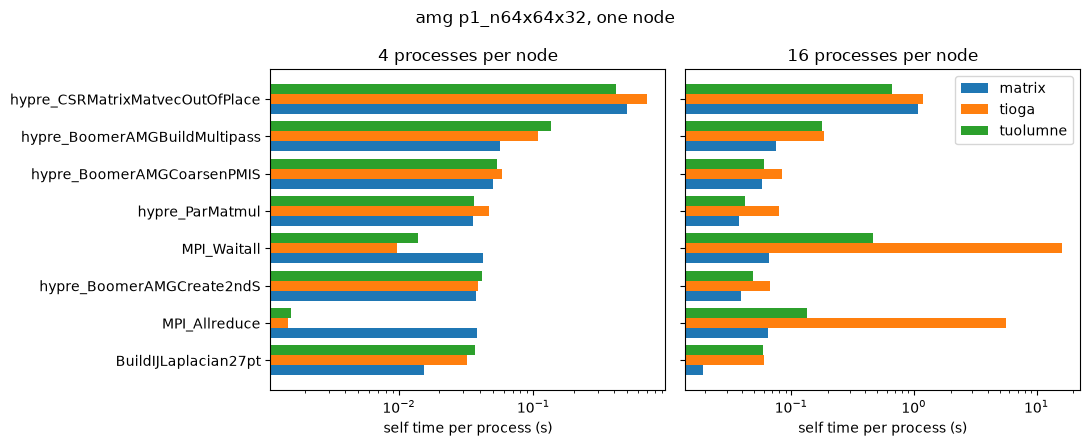

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
names = at4.max(axis=1).nlargest(8).index[::-1]
for ax, ppn in zip(axes, [4, 16]):
    t = wide[wide["ppn"] == ppn].set_index("name").reindex(names)
    y = np.arange(len(names))
    for i, system in enumerate(SYSTEMS):
        ax.barh(y + (i - 1) * 0.27, t[system], height=0.27, label=system)
    ax.set_xscale("log")
    ax.set_xlabel("self time per process (s)")
    ax.set_title(f"{ppn} processes per node")
axes[0].set_yticks(np.arange(len(names)), names)
axes[1].legend()
fig.suptitle("amg p1_n64x64x32, one node")
fig.tight_layout()
fig.savefig("../figures/systems-functions.png", dpi=120)

![Self time per process of the same functions on three systems](../figures/systems-functions.png)

At 4 processes per node matrix spends the most time in MPI, but at 16 the MPI bars of tioga are longer than every other bar.
The compute bars of tioga stay close to those of matrix.

## 4. Check the pattern over all 108 settings

One setting can mislead.
Repeat the comparison for every setting that ran on all three systems, divide each function's time by its fastest system, and take the median over the settings.

In [8]:
keep = DataFrame.from_pandas(common[setting])
info = runs.merge(keep, on=setting)
fn = per_function(info["run"].to_pandas().tolist(), info[["run", "system", *setting]]).to_pandas()
wide = fn.pivot_table(values="self_pp", index=[*setting, "name"], columns="system").dropna()
rel = wide[SYSTEMS].div(wide[SYSTEMS].min(axis=1), axis=0)
rel["many"] = wide.index.get_level_values("ppn") >= 16
top = wide.groupby("name")["matrix"].sum().nlargest(14).index
table = rel[rel.index.get_level_values("name").isin(top)].groupby(["many", "name"])[SYSTEMS].median()
display(table.round(2))

system                                 matrix   tioga  tuolumne
many  name                                                     
False MPI_Allreduce                      3.46    1.00      1.11
      MPI_Waitall                        1.54    1.08      1.37
      hypre_BoomerAMGBuildMultipass      1.00    1.53      1.66
      hypre_BoomerAMGCoarsenPMIS         1.00    1.17      1.08
      hypre_BoomerAMGCreate2ndS          1.00    1.09      1.07
      hypre_BoomerAMGCreateS             1.00    2.09      1.76
      hypre_CSRMatrixMatvecOutOfPlace    1.33    1.30      1.00
      hypre_CSRMatrixMatvecT             1.09    1.22      1.00
      hypre_ParCSRRelax                  1.40    1.27      1.00
      hypre_ParMatmul                    1.00    1.31      1.05
      hypre_ParMatmul_RowSizes           1.13    1.19      1.00
      hypre_SeqVectorAxpy                2.05    1.76      1.00
      hypre_SeqVectorCopy                1.81    1.98      1.00
      hypre_SeqVectorInnerProd           1.00    1.55      1.03
True  MPI_Allreduce                      1.55  320.54      1.00
      MPI_Waitall                        1.00  338.27      2.01
      hypre_BoomerAMGBuildMultipass      1.00    1.40      1.60
      hypre_BoomerAMGCoarsenPMIS         1.02    1.16      1.00
      hypre_BoomerAMGCreate2ndS          1.00    1.16      1.19
      hypre_BoomerAMGCreateS             1.00    2.25      1.00
      hypre_CSRMatrixMatvecOutOfPlace    1.69    2.28      1.00
      hypre_CSRMatrixMatvecT             1.31    2.08      1.00
      hypre_ParCSRRelax                  1.17    3.28      1.00
      hypre_ParMatmul                    1.00    1.88      1.17
      hypre_ParMatmul_RowSizes           1.04    1.43      1.00
      hypre_SeqVectorAxpy                1.93    3.03      1.00
      hypre_SeqVectorCopy                2.37    2.86      1.00
      hypre_SeqVectorInnerProd           1.40    1.65      1.00

`many` is True from 16 processes per node.
Three patterns hold over all the settings.

- tuolumne wins the solve: the matrix-vector products, the relaxation and the vector operations such as `hypre_SeqVectorAxpy`, which stream through memory.
  matrix takes up to 2.4 times as long there.
- matrix wins the setup: the coarse grids of `hypre_BoomerAMGCreateS`, `hypre_BoomerAMGBuildMultipass` and `hypre_ParMatmul`, which build new matrices.
  tioga and tuolumne take up to 2.3 times as long there.
- From 16 processes per node tioga loses in MPI, where `MPI_Waitall` and `MPI_Allreduce` take more than 300 times longer than on the fastest system, while its compute functions lose 1.2 to 3.3 times.

Below 16 processes per node matrix is the slow one in `MPI_Allreduce`, at 3.5 times tioga.

So amg wins on matrix when the setup is a large part of the run, and on tuolumne when the solve is.
The trace shows where each system spends the time, not the hardware cause, but the solve functions are the ones that read the most memory.

## What you built

You compared the same settings on three systems without a baseline system, and traced each system's wins and losses to the functions behind them.

- The MPI side of tioga's loss: [Measure how much of main is MPI](07-mpi-share-of-main.ipynb)
- Next: [Check how repeatable the runs are](09-spread-and-repeatability.ipynb)